# Credit-offer experiment walkthrough

> **Everything in this notebook is synthetic.** The simulated accounts and planted effects are teaching assumptions—not customer observations, policy evidence, or a forecast. The exercise assumes no interference between accounts and only a 90-day outcome window.

This walkthrough follows the experiment from a reproducible 1:1 account-level assignment through power planning, primary and guardrail analysis, risk-band exploration, and a cautious simulation-only decision. Reusable logic lives in `src/`; this notebook presents and interprets it.

In [3]:
from pathlib import Path
import importlib
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "config.py").exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

import config as config_module
import src.simulate as simulation

importlib.reload(config_module)
importlib.reload(simulation)
DEFAULT_CONFIG = config_module.DEFAULT_CONFIG
simulated = simulation.simulate_accounts(
    n_accounts=DEFAULT_CONFIG.n_accounts,
    config=DEFAULT_CONFIG,
    random_state=DEFAULT_CONFIG.seed,
)
print(f"Synthetic accounts: {len(simulated):,}")
print("Risk-band mix:")
display(simulated["risk_band"].value_counts(normalize=True).sort_index().rename("share").to_frame())
print(f"Treatment share: {simulated['treatment'].mean():.3f}")

Synthetic accounts: 5,000
Risk-band mix:


,share
risk_band,
high,0.0358
low,0.6956
medium,0.2686


Treatment share: 0.499


## 1. Simulated population and assignment

The simulator creates pre-period spend and account features, derives a logistic PD and low/medium/high bands, then plants band-specific spend and delinquency effects. Assignment uses a separate seeded random stream. The displayed mix is a useful sanity check that all three planned bands are represented.

In [4]:
import pandas as pd

simulation_summary = simulated.groupby("risk_band").agg(
    accounts=("account_id", "size"),
    mean_pd=("pd", "mean"),
    planted_spend_lift=("true_spend_effect", "mean"),
    planted_delinquency_lift=("true_delinquency_effect", "mean"),
)
display(simulation_summary)
assert simulated["risk_band"].nunique() == 3
assert simulated["treatment"].isin([0, 1]).all()

,accounts,mean_pd,planted_spend_lift,planted_delinquency_lift
risk_band,,,,
high,179,0.429724,0.18,0.025
low,3478,0.078696,0.08,0.000
medium,1343,0.217868,0.12,0.000


## 2. Power planning

Planning uses the simulated control-arm mean and variance as baseline inputs. The CUPED variance multiplier is measured from this generated dataset rather than assumed. The calculation is a normal approximation for a two-sided 5% test and 80% target power; it does not establish that the sample is adequate for the delinquency guardrail.

In [5]:
from src.analysis import (
    estimate_effects_by_risk_band,
    make_cli_recommendation,
    summarize_experiment,
)
from src.power import make_power_curve, power_summary

control = simulated.loc[simulated["treatment"] == 0]
baseline_mean = float(control["post_spend"].mean())
baseline_variance = float(control["post_spend"].var(ddof=1))
analysis = summarize_experiment(simulated, outcome_col="post_spend")
variance_ratio = float(analysis["cuped_variance_reduction_ratio"])

planning = power_summary(
    baseline_mean=baseline_mean,
    baseline_variance=baseline_variance,
    effect_fraction=0.05,
    variance_reduction_fraction=variance_ratio,
)
pd.Series(planning, name="value").to_frame()

,value
baseline_mean,184.079254
baseline_variance,29164.998101
effect_fraction,0.050000
mde_absolute,9.203963
alpha,0.050000
power,0.800000
unadjusted_per_arm_n,5405.000000
cuped_per_arm_n,133.000000


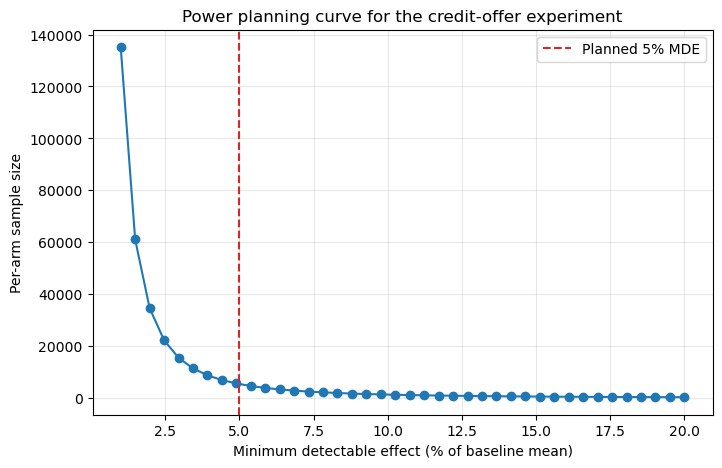

Measured CUPED variance ratio: 0.024
Approximate per-arm n at 5% MDE: unadjusted=5,405, CUPED=133


In [6]:
import matplotlib.pyplot as plt

mde_fractions, per_arm_sizes, power_figure, power_axes = make_power_curve(
    baseline_mean=baseline_mean,
    baseline_variance=baseline_variance,
)
power_axes.axvline(5.0, color="tab:red", linestyle="--", label="Planned 5% MDE")
power_axes.legend()
plt.show()
plt.close(power_figure)

print(f"Measured CUPED variance ratio: {variance_ratio:.3f}")
print(
    "Approximate per-arm n at 5% MDE: "
    f"unadjusted={planning['unadjusted_per_arm_n']:,}, "
    f"CUPED={planning['cuped_per_arm_n']:,}"
)

## 3. Primary outcome and guardrail

The primary estimate is the treatment-minus-control difference in mean 90-day spend, with a two-sided 95% confidence interval. The guardrail is the treatment-minus-control difference in the simulated 60+ DPD rate. The decision rule requires positive spend with its interval above zero and a one-sided 95% upper guardrail bound below the predeclared 0.5 percentage-point margin.

In [7]:
summary = summarize_experiment(simulated, outcome_col="post_spend")
summary_view = {
    "treatment_accounts": summary["n_treated"],
    "control_accounts": summary["n_control"],
    "SRM_p_value": summary["split_check"]["p_value"],
    "spend_effect": summary["effect_size"],
    "spend_95pct_CI": (summary["effect_ci_lower"], summary["effect_ci_upper"]),
    "spend_p_value": summary["effect_p_value"],
    "CUPED_effect": summary["cuped_estimate"],
    "OLS_effect": summary["ols_estimate"],
    "delinquency_risk_difference": summary["guardrail_risk_difference"],
    "delinquency_95pct_CI": (summary["guardrail_ci_lower"], summary["guardrail_ci_upper"]),
}
pd.Series(summary_view, name="estimate").to_frame()

,estimate
treatment_accounts,2497
control_accounts,2503
SRM_p_value,0.932378
spend_effect,20.500286
spend_95pct_CI,"(9.90399452476811, 31.096578145520652)"
spend_p_value,0.00015
CUPED_effect,17.550774
OLS_effect,17.551845
delinquency_risk_difference,0.00078
delinquency_95pct_CI,"(-0.01945059882379578, 0.021009961069277425)"


In [8]:
decision = make_cli_recommendation(simulated, outcome_col="post_spend")
print("Simulation-only decision:", decision)
print(f"Guardrail margin: {decision['guardrail_margin']:.3%}")

Simulation-only decision: {'decision': 'do_not_ship', 'reason': 'Spend effect is positive, but the guardrail upper bound exceeds the predeclared margin.', 'spend_positive': True, 'spend_ci_excludes_zero': True, 'guardrail_ok': False, 'spend_effect': 20.50028633514438, 'spend_ci_lower': 9.90399452476811, 'spend_ci_upper': 31.096578145520652, 'guardrail_risk_difference': 0.0007796811227408218, 'guardrail_upper_one_sided_95': 0.017757467248802332, 'guardrail_margin': 0.005}
Guardrail margin: 0.500%


## 4. Risk-band effects (exploratory)

Band-level estimates are descriptive and have not been adjusted for multiple comparisons. Always inspect the arm denominators alongside intervals; sparse high-risk events can make guardrail estimates imprecise. These subgroup estimates must not be treated as confirmatory proof.

In [9]:
band_effects = estimate_effects_by_risk_band(simulated, outcome_col="post_spend")
arm_counts = simulated.groupby(["risk_band", "treatment"]).size().unstack(fill_value=0)
arm_counts = arm_counts.rename(columns={0: "n_control", 1: "n_treatment"})
display(arm_counts.join(band_effects.set_index("risk_band")))

,n_control,n_treatment,spend_effect,spend_ci_lower,spend_ci_upper,delinquency_risk_difference,delinquency_ci_upper
risk_band,,,,,,,
high,97,82,35.426017,-26.159991,97.012024,-0.049158,0.096173
low,1728,1750,23.413170,12.161575,34.664766,0.016674,0.035787
medium,678,665,13.800099,-10.962281,38.562478,-0.019970,0.027838


## 5. A/A calibration and repeated peeking

A correctly run A/A experiment should reject near the nominal alpha level over many repetitions. Repeatedly testing the same accumulating data and stopping at the first significant result inflates the false-positive probability. The examples below use fixed seeds and are demonstrations, not estimates of a real experiment's error rate.

In [10]:
from src.pitfalls import run_aa_test, run_peeking_demo

aa_result = run_aa_test(n_simulations=300, n_accounts=1500, seed=DEFAULT_CONFIG.seed + 101)
peeking_result = run_peeking_demo(days=10, n_accounts=1500, seed=DEFAULT_CONFIG.seed + 202)
print("A/A false-positive rate:", aa_result["false_positive_rate"])
print("Peeking false-positive rate:", peeking_result["false_positive_rate"])
print("Single-final-look comparator:", peeking_result["aa_false_positive_rate"])

A/A false-positive rate: 0.04
Peeking false-positive rate: 0.165
Single-final-look comparator: 0.04


## 6. Interpretation and limits

In this seeded run, spend is higher in treatment and its unadjusted interval excludes zero. However, the one-sided 95% guardrail upper bound is above the illustrative 0.5 pp margin, so the coded decision is **do not ship based on this simulated experiment**. This is a failure to establish the required guardrail criterion—not evidence that the true risk effect is harmful. The high-risk subgroup is small, and its interval is especially wide.

The exercise omits take-up/noncompliance, interference, long-term credit outcomes, operational costs, and real portfolio calibration. The power calculation is a normal approximation; the CUPED sample-size comparison is based on variance reduction measured in this one synthetic draw. No result here supports a real credit decision.

## 7. Automated checks

Run the repository tests to verify the simulation, analysis decision rule, power calculation, and A/A demonstration. A successful test run is a code check only; it does not validate the synthetic assumptions for a real portfolio.

In [11]:
import pytest

test_exit_code = pytest.main(["-q", str(REPO_ROOT / "tests")])
assert test_exit_code == 0

............                                                             [100%]
12 passed in 1.70s
